# Task 1: Train a Baseline CNN on MNIST


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
torch.manual_seed(42)
device = torch.device('cpu')
transform = transforms.Compose([
    transforms.ToTensor()
])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x
model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 2
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.4f}")
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

clean_accuracy = 100 * correct / total
print(f"\nClean Test Accuracy: {clean_accuracy:.2f}%")

Epoch 1/2 - Loss: 0.2312
Epoch 2/2 - Loss: 0.0627

Clean Test Accuracy: 98.62%


# Task 2: Implement and Evaluate FGSM Attack


In [3]:
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def evaluate_fgsm(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    for data, target in test_loader:
        data, target = data.to(device), target.to(device)

        data.requires_grad = True

        output = model(data)
        loss = nn.CrossEntropyLoss()(output, target)

        model.zero_grad()

        loss.backward()

        data_grad = data.grad.data

        perturbed_data = fgsm_attack(data, epsilon, data_grad)

        output = model(perturbed_data)
        _, final_pred = torch.max(output.data, 1)

        total += target.size(0)
        correct += (final_pred == target).sum().item()

    accuracy = 100.0 * correct / total
    print(f"Epsilon: {epsilon:.2f} -> Adversarial Test Accuracy: {accuracy:.2f}%")
    return accuracy

epsilons = [0.05, 0.10, 0.20, 0.30]
print("Evaluating Baseline CNN under FGSM attack:")
for eps in epsilons:
    evaluate_fgsm(model, device, test_loader, eps)

Evaluating Baseline CNN under FGSM attack:
Epsilon: 0.05 -> Adversarial Test Accuracy: 94.25%
Epsilon: 0.10 -> Adversarial Test Accuracy: 82.14%
Epsilon: 0.20 -> Adversarial Test Accuracy: 27.85%
Epsilon: 0.30 -> Adversarial Test Accuracy: 2.08%


# Task 3: Implement and Evaluate Projected Gradient Descent (PGD) Attack


In [4]:
def pgd_attack(model, images, labels, epsilon, alpha=None, num_iter=10):
    if alpha is None:
        alpha = epsilon / 4.0

    random_perturbation = torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(images.device)
    perturbed_images = images + random_perturbation
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for i in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = nn.CrossEntropyLoss()(outputs, labels)

        model.zero_grad()
        loss.backward()

        data_grad = perturbed_images.grad.data
        perturbed_images = perturbed_images + alpha * data_grad.sign()

        eta = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + eta, min=0.0, max=1.0).detach()

    return perturbed_images

def evaluate_pgd(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    for data, target in test_loader:
        data, target = data.to(device), target.to(device)

        perturbed_data = pgd_attack(model, data, target, epsilon, alpha=epsilon/4.0, num_iter=10)

        output = model(perturbed_data)
        _, final_pred = torch.max(output.data, 1)

        total += target.size(0)
        correct += (final_pred == target).sum().item()

    accuracy = 100.0 * correct / total
    print(f"Epsilon: {epsilon:.2f} -> PGD Test Accuracy: {accuracy:.2f}%")
    return accuracy

epsilons = [0.05, 0.10, 0.20, 0.30]
print("Evaluating Baseline CNN under PGD attack (10 iterations, step size eps/4):")
for eps in epsilons:
    evaluate_pgd(model, device, test_loader, eps)

Evaluating Baseline CNN under PGD attack (10 iterations, step size eps/4):
Epsilon: 0.05 -> PGD Test Accuracy: 92.75%
Epsilon: 0.10 -> PGD Test Accuracy: 69.65%
Epsilon: 0.20 -> PGD Test Accuracy: 0.58%
Epsilon: 0.30 -> PGD Test Accuracy: 0.00%


# Task 4: Visualize Original and FGSM Adversarial Digits

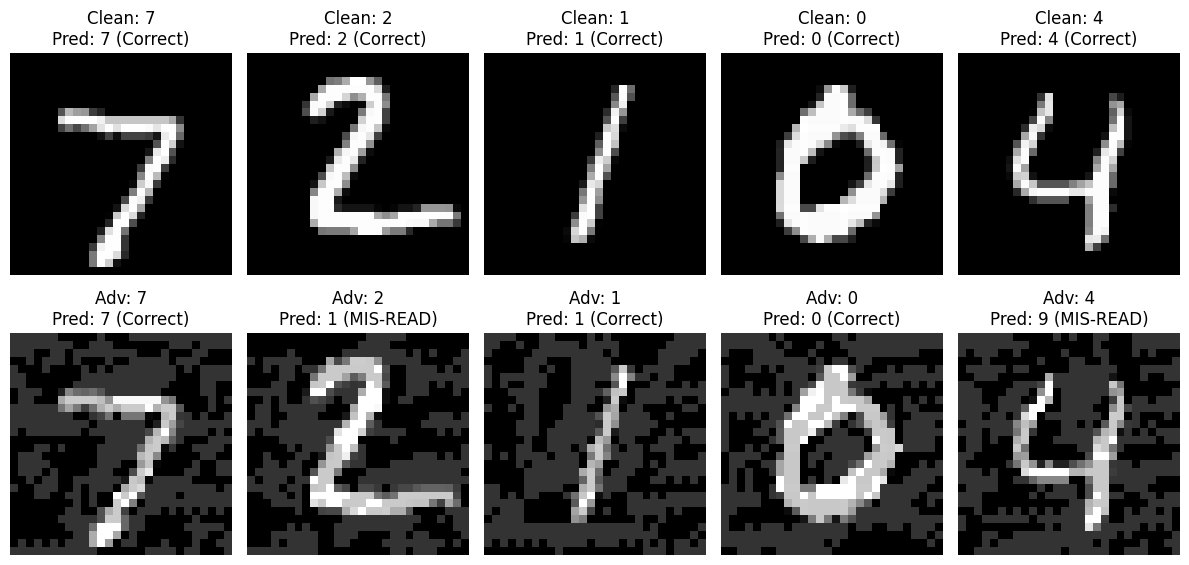

In [5]:
import matplotlib.pyplot as plt

model.eval()

data_iter = iter(test_loader)
images, labels = next(data_iter)

num_samples = 5
images = images[:num_samples].to(device)
labels = labels[:num_samples].to(device)

images.requires_grad = True

outputs = model(images)
loss = nn.CrossEntropyLoss()(outputs, labels)

model.zero_grad()
loss.backward()

data_grad = images.grad.data
perturbed_images = fgsm_attack(images, 0.20, data_grad)

with torch.no_grad():
    clean_outputs = model(images)
    _, clean_preds = torch.max(clean_outputs, 1)

    adv_outputs = model(perturbed_images)
    _, adv_preds = torch.max(adv_outputs, 1)

images_np = images.squeeze().detach().cpu().numpy()
perturbed_images_np = perturbed_images.squeeze().detach().cpu().numpy()
labels_np = labels.cpu().numpy()
clean_preds_np = clean_preds.cpu().numpy()
adv_preds_np = adv_preds.cpu().numpy()

fig, axes = plt.subplots(2, num_samples, figsize=(12, 6))

for i in range(num_samples):

    axes[0, i].imshow(images_np[i], cmap='gray')
    is_correct_clean = "(Correct)" if clean_preds_np[i] == labels_np[i] else "(Wrong)"
    axes[0, i].set_title(f"Clean: {labels_np[i]}\nPred: {clean_preds_np[i]} {is_correct_clean}")
    axes[0, i].axis('off')


    axes[1, i].imshow(perturbed_images_np[i], cmap='gray')
    status = "Correct" if adv_preds_np[i] == labels_np[i] else "MIS-READ"
    axes[1, i].set_title(f"Adv: {labels_np[i]}\nPred: {adv_preds_np[i]} ({status})")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Task 5: Adversarial Training (Defending the Model)


In [6]:

adv_epochs = 2
eps_train = 0.20


model.train()

for epoch in range(adv_epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)


        batch_size = images.size(0)
        half_batch = batch_size // 2

        clean_images = images[:half_batch]
        clean_labels = labels[:half_batch]

        adv_inputs = images[half_batch:]
        adv_labels = labels[half_batch:]

        adv_inputs.requires_grad = True
        outputs_temp = model(adv_inputs)
        loss_temp = criterion(outputs_temp, adv_labels)

        model.zero_grad()
        loss_temp.backward()

        data_grad = adv_inputs.grad.data
        perturbed_inputs = fgsm_attack(adv_inputs, eps_train, data_grad).detach()

        mixed_images = torch.cat([clean_images, perturbed_inputs], dim=0)
        mixed_labels = torch.cat([clean_labels, adv_labels], dim=0)

        optimizer.zero_grad()
        outputs = model(mixed_images)
        loss = criterion(outputs, mixed_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_size

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Adversarial Fine-tuning Epoch {epoch+1}/{adv_epochs} - Loss: {epoch_loss:.4f}")

Adversarial Fine-tuning Epoch 1/2 - Loss: 0.3026
Adversarial Fine-tuning Epoch 2/2 - Loss: 0.2028


In [7]:

model.eval()

correct_clean = 0
total_clean = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total_clean += labels.size(0)
        correct_clean += (predicted == labels).sum().item()

rob_clean_acc = 100 * correct_clean / total_clean
print(f"Hardened Model - Clean Test Accuracy: {rob_clean_acc:.2f}%")

print("Hardened Model under FGSM Attack:")
rob_fgsm_acc = evaluate_fgsm(model, device, test_loader, 0.20)

print("Hardened Model under PGD Attack:")
rob_pgd_acc = evaluate_pgd(model, device, test_loader, 0.20)

Hardened Model - Clean Test Accuracy: 98.90%
Hardened Model under FGSM Attack:
Epsilon: 0.20 -> Adversarial Test Accuracy: 90.05%
Hardened Model under PGD Attack:
Epsilon: 0.20 -> PGD Test Accuracy: 43.80%


# Task 6: Accuracy vs $\epsilon$ Curve and Performance Summary Table


<>:13: SyntaxWarning: invalid escape sequence '\e'
<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\e'
<>:14: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_423/3261454109.py:13: SyntaxWarning: invalid escape sequence '\e'
  plt.title('Baseline Model Accuracy vs. Perturbation Budget (\epsilon)')
/tmp/ipykernel_423/3261454109.py:14: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('Epsilon (\epsilon)')


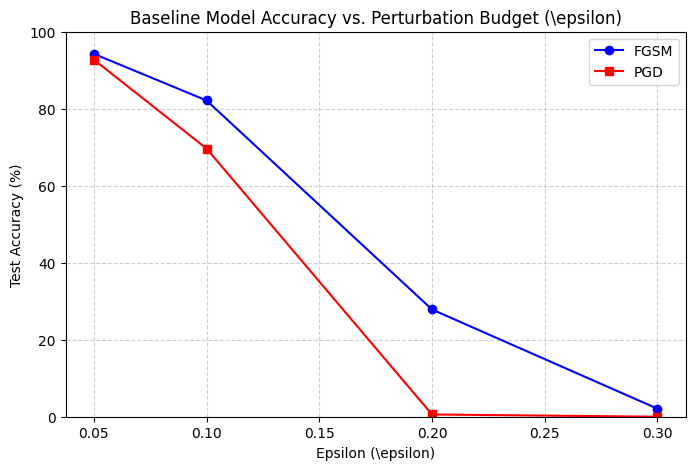

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
epsilons = [0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = [94.25, 82.14, 27.85, 2.08]
pgd_accuracies = [92.75, 69.65, 0.58, 0.00]

plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, 'o-', label='FGSM', color='blue')
plt.plot(epsilons, pgd_accuracies, 's-', label='PGD', color='red')
plt.title('Baseline Model Accuracy vs. Perturbation Budget (\epsilon)')
plt.xlabel('Epsilon (\epsilon)')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.ylim(0, 100)
plt.show()

In [9]:

data = {
    'Evaluation Metric': [
        'Clean Test Accuracy',
        'FGSM Accuracy (Εpsilon = 0.20)',
        'PGD Accuracy (Εpsilon = 0.20)'
    ],
    'Baseline Model': [
        '98.62%',
        '27.85%',
        '0.58%'
    ],
    'Adversarially Trained Model': [
        f'{rob_clean_acc:.2f}%',
        f'{rob_fgsm_acc:.2f}%',
        f'{rob_pgd_acc:.2f}%'
    ]
}

df_summary = pd.DataFrame(data)
display(df_summary)

,Evaluation Metric,Baseline Model,Adversarially Trained Model
0,Clean Test Accuracy,98.62%,98.90%
1,FGSM Accuracy (Εpsilon = 0.20),27.85%,90.05%
2,PGD Accuracy (Εpsilon = 0.20),0.58%,43.80%
